# Colorectal cancer RNA-seq from raw reads: Salmon → DESeq2 → GO/GSEA

Matched normal mucosa, primary tumour and liver metastasis from colorectal cancer patients, processed from FASTQ to pathways. Data: [GSE50760](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE50760) (ENA project `PRJNA218851`, Kim et al., 2015), 18 patients with all three tissues.

Two questions: what separates tumour from normal tissue in the same patient, and what separates the liver metastasis from the primary tumour.

This run uses 6 patients (18 samples) and the first 2M read pairs per sample, which keeps the whole thing within a free Colab session (about an hour, mostly download and indexing). Finished steps are cached, so re-running cells after a dropped session doesn't redo them.

| Step | What | Tools |
|---|---|---|
| 1 | Sample sheet from ENA and GEO | ENA API, GEOparse |
| 2 | Stream the first N read pairs per sample | curl |
| 3 | Trimming and QC | fastp, FastQC, MultiQC |
| 4 | Quantification against GENCODE v46 | Salmon |
| 5 | Transcript to gene counts | tx2gene from GENCODE headers |
| 6 | Differential expression, `~ patient + tissue` | pydeseq2 |
| 7 | PCA, volcano, heatmap, known-marker check | matplotlib, seaborn |
| 8 | GO (Enrichr) and GSEA (Hallmark) | gseapy |

Normal, primary and metastasis come from the same people, so patient is part of the model (`~ patient + tissue`). That keeps differences between individuals from drowning out the tissue effect.

## 0. Setup and parameters

In [ ]:
import os, shutil, glob

!apt-get -qq update > /dev/null
!apt-get -qq install -y fastp fastqc > /dev/null
!pip -q install pydeseq2 gseapy GEOparse multiqc

if not shutil.which("salmon"):
    !wget -q https://github.com/COMBINE-lab/salmon/releases/download/v1.10.0/salmon-1.10.0_linux_x86_64.tar.gz -O /content/salmon.tar.gz
    !tar xzf /content/salmon.tar.gz -C /content
    salmon_bin = glob.glob("/content/salmon*/bin")[0]
    os.environ["PATH"] = salmon_bin + ":" + os.environ["PATH"]
!salmon --version
!fastp --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.8/5.8 MB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 MB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 63.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.1/41.1 MB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━

In [ ]:
import os, re, io, gzip, json, glob, time, shutil, subprocess, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

PROJECT = "PRJNA218851"
GSE_ID = "GSE50760"
N_PATIENTS = 6
TISSUES = ["normal", "primary", "metastasis"]
READS_PER_SAMPLE = 2_000_000
THREADS = os.cpu_count() or 2
MANUAL_SAMPLE_CSV = None
USE_DRIVE = False

GENCODE_URL = "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_46/gencode.v46.transcripts.fa.gz"
FDR_CUT, LFC_CUT = 0.05, 1.0

WORK = "/content/crc_rnaseq"
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/crc_rnaseq"
RAW, TRIM, QC, REF, QUANT, OUT = (f"{WORK}/{d}" for d in ["raw", "trim", "qc", "ref", "quant", "results"])
IDX = f"{REF}/salmon_index"
for d in [RAW, TRIM, QC, REF, QUANT, OUT]:
    os.makedirs(d, exist_ok=True)

def natural(s):
    return [int(x) if x.isdigit() else x for x in re.split(r"(\d+)", str(s))]

def sort_samples(df, tissue_first=False):
    d = df.copy()
    d["_p"] = d["patient"].astype(str).str.extract(r"(\d+)")[0].astype(float).fillna(0)
    d["_t"] = d["tissue"].astype(str).map({"normal": 0, "primary": 1, "metastasis": 2})
    keys = ["_t", "_p"] if tissue_first else ["_p", "_t"]
    return d.sort_values(keys).drop(columns=["_p", "_t"]).reset_index(drop=True)

INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
TISSUE_PAL = {"normal": BLUE, "primary": ORANGE, "metastasis": AQUA}
DIV_CMAP = LinearSegmentedColormap.from_list("div_bwr", ["#1c5cab", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})
print("Work dir:", WORK, "| threads:", THREADS)

Work dir: /content/crc_rnaseq | threads: 2


## 1. Samples and metadata

Run accessions and FASTQ links come from ENA; tissue and patient labels come from GEO. The cell prints a patient × tissue table so the parsing can be checked, and `MANUAL_SAMPLE_CSV` overrides it if the automatic parsing gets something wrong.

In [ ]:
import requests

def ena_runs(project):
    base = "https://www.ebi.ac.uk/ena/portal/api/filereport"
    want = ["run_accession", "experiment_alias", "sample_alias", "run_alias", "sample_title",
            "experiment_title", "library_layout", "fastq_ftp", "read_count"]
    for fields in (",".join(want), ""):
        url = f"{base}?accession={project}&result=read_run&format=tsv&download=true"
        if fields:
            url += f"&fields={fields}"
        r = requests.get(url, timeout=90)
        if r.ok and r.text.strip():
            return pd.read_csv(io.StringIO(r.text), sep="\t")
    r.raise_for_status()

def geo_meta(gse_id):
    import GEOparse
    gse = GEOparse.get_GEO(geo=gse_id, destdir=f"{WORK}/geo", silent=True)
    rows = []
    for gsm_id, gsm in gse.gsms.items():
        chars = gsm.metadata.get("characteristics_ch1", [])
        rec = {"gsm": gsm_id, "geo_title": gsm.metadata.get("title", [""])[0], "geo_chars": " | ".join(chars)}
        for c in chars:
            if ":" in c:
                k, v = c.split(":", 1)
                rec["char_" + k.strip().lower()] = v.strip()
        rows.append(rec)
    return pd.DataFrame(rows)

def infer_tissue(text):
    t = text.lower()
    if re.search(r"metast", t):
        return "metastasis"
    if re.search(r"normal|adjacent|healthy|non-?tumou?r", t):
        return "normal"
    if re.search(r"primary|tumou?r|cancer|carcinoma|crc", t):
        return "primary"
    return None

def infer_patient(row):
    for k in row.index:
        if k.startswith("char_") and re.search(r"patient|individual|subject|donor|case|pair", k):
            return str(row[k]).strip()
    title = str(row.get("geo_title", "")) or str(row.get("experiment_title", ""))
    m = re.search(r"(\d+)\s*[-_]\s*\d+\s*$", title.strip())
    if m:
        return m.group(1)
    m = re.search(r"(?:patient|pt|case|individual|subject)[ _\-]?(\d+)", title, re.I)
    if m:
        return m.group(1)
    nums = re.findall(r"\d+", title)
    return nums[-1] if nums else None

if MANUAL_SAMPLE_CSV:
    samples = pd.read_csv(MANUAL_SAMPLE_CSV, dtype=str).fillna("")
    samples["layout"] = np.where(samples["fastq_2"] == "", "SINGLE", "PAIRED")
else:
    ena = ena_runs(PROJECT)
    alias_cols = [c for c in ["experiment_alias", "sample_alias", "run_alias", "experiment_title", "sample_title"] if c in ena.columns]
    ena["gsm"] = ena[alias_cols].astype(str).agg(" ".join, axis=1).str.extract(r"(GSM\d+)")[0]
    try:
        geo = geo_meta(GSE_ID)
        meta = ena.merge(geo, on="gsm", how="left")
    except Exception as e:
        print("GEO unavailable, using ENA titles only:", e)
        meta = ena.copy()
        meta["geo_title"] = meta.get("experiment_title", "")
        meta["geo_chars"] = meta.get("sample_title", "")
    tissue_cols = [c for c in meta.columns if c.startswith("char_") and re.search(r"tissue|type|source|disease|condition|sample", c)]
    def tissue_text(r):
        txt = " ".join(str(r[c]) for c in tissue_cols if pd.notna(r[c]))
        return txt if txt.strip() else f"{r.get('geo_title', '')} {r.get('geo_chars', '')}"
    meta["tissue"] = meta.apply(lambda r: infer_tissue(tissue_text(r)) or infer_tissue(f"{r.get('geo_title', '')} {r.get('geo_chars', '')}"), axis=1)
    meta["patient"] = meta.apply(infer_patient, axis=1)
    meta = meta.dropna(subset=["tissue", "patient"])

    def split_urls(u):
        parts = [p for p in str(u).split(";") if p and p != "nan"]
        r1 = next((p for p in parts if p.endswith("_1.fastq.gz")), None)
        r2 = next((p for p in parts if p.endswith("_2.fastq.gz")), None)
        if r1 is None:
            single = [p for p in parts if not p.endswith("_2.fastq.gz")]
            r1 = single[0] if single else None
        return pd.Series({"fastq_1": r1, "fastq_2": r2})
    meta = pd.concat([meta, meta["fastq_ftp"].apply(split_urls)], axis=1).dropna(subset=["fastq_1"])
    meta["layout"] = np.where(meta["fastq_2"].notna(), "PAIRED", "SINGLE")
    meta["run"] = meta["run_accession"]

    print("Samples parsed:", len(meta))
    ct = pd.crosstab(meta["patient"], meta["tissue"])
    ct = ct.loc[sorted(ct.index, key=natural)]
    print(ct.to_string())

    complete = [p for p in ct.index if all(ct.loc[p].get(t, 0) >= 1 for t in TISSUES)]
    chosen = complete[:N_PATIENTS]
    if not chosen:
        raise RuntimeError(
            "No patients have all the selected tissues. Check the table above and either change TISSUES, "
            "or pass a sample sheet via MANUAL_SAMPLE_CSV (columns: run,patient,tissue,fastq_1,fastq_2).")
    samples = (meta[meta["patient"].isin(chosen) & meta["tissue"].isin(TISSUES)]
               .drop_duplicates(["patient", "tissue"])
               [["run", "patient", "tissue", "layout", "fastq_1", "fastq_2"]])

samples["patient"] = "P" + samples["patient"].astype(str)
samples["tissue"] = pd.Categorical(samples["tissue"], categories=[t for t in ["normal", "primary", "metastasis"] if t in set(samples["tissue"])])
samples = sort_samples(samples)
print(f"\nSelected: {samples['patient'].nunique()} patients, {len(samples)} samples, layout: {samples['layout'].unique()}")
samples

Samples parsed: 54
tissue   metastasis  normal  primary
patient                             
2                 1       1        1
3                 1       1        1
5                 1       1        1
6                 1       1        1
7                 1       1        1
8                 1       1        1
9                 1       1        1
10                1       1        1
12                1       1        1
13                1       1        1
17                1       1        1
18                1       1        1
19                1       1        1
20                1       1        1
21                1       1        1
22                1       1        1
23                1       1        1
24                1       1        1

Selected: 6 patients, 18 samples, layout: <ArrowStringArray>
['PAIRED']
Length: 1, dtype: str


,run,patient,tissue,layout,fastq_1,fastq_2
0,SRR975569,P2,normal,PAIRED,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975569/...,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975569/...
1,SRR975551,P2,primary,PAIRED,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975551/...,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975551/...
2,SRR975587,P2,metastasis,PAIRED,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975587/...,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975587/...
3,SRR975570,P3,normal,PAIRED,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975570/...,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975570/...
4,SRR975552,P3,primary,PAIRED,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975552/...,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975552/...
5,SRR975588,P3,metastasis,PAIRED,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975588/...,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975588/...
6,SRR975571,P5,normal,PAIRED,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975571/...,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975571/...
7,SRR975553,P5,primary,PAIRED,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975553/...,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975553/...
8,SRR975589,P5,metastasis,PAIRED,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975589/...,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975589/...
9,SRR975572,P6,normal,PAIRED,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975572/...,ftp.sra.ebi.ac.uk/vol1/fastq/SRR975/SRR975572/...


## 2. Downloading reads

Full FASTQ files run to gigabytes, so each file is streamed and cut after the first `READS_PER_SAMPLE` read pairs. Both mates are cut at the same point, so pairs stay intact.

Caveat: the head of a file is not a random sample in the strict sense. For a group comparison that shouldn't matter, but it is a limitation.

In [ ]:
def fetch_head(url, out, n_reads):
    if os.path.exists(out) and os.path.getsize(out) > 0:
        return out
    full = url if url.startswith("http") else "https://" + url
    tmp = out + ".part"
    cmd = f"curl -sS -L --retry 5 --retry-delay 3 '{full}' | gzip -dc | head -n {4 * n_reads} | gzip -1 > '{tmp}'"
    subprocess.run(["bash", "-c", cmd], check=False)
    if not os.path.exists(tmp) or os.path.getsize(tmp) == 0:
        raise RuntimeError(f"Download failed: {full}")
    os.replace(tmp, out)
    return out

jobs = []
for r in samples.itertuples():
    jobs.append((r.fastq_1, f"{RAW}/{r.run}_1.fastq.gz"))
    if r.layout == "PAIRED":
        jobs.append((r.fastq_2, f"{RAW}/{r.run}_2.fastq.gz"))

t0 = time.time()
with ThreadPoolExecutor(max_workers=4) as ex:
    futs = [ex.submit(fetch_head, u, o, READS_PER_SAMPLE) for u, o in jobs]
    for i, f in enumerate(futs, 1):
        f.result()
        if i % 6 == 0 or i == len(futs):
            print(f"  files downloaded: {i}/{len(futs)}  ({time.time() - t0:.0f} s)")
print("Raw size:", subprocess.run(["du", "-sh", RAW], capture_output=True, text=True).stdout.split()[0])

  files downloaded: 6/36  (319 s)
  files downloaded: 12/36  (500 s)
  files downloaded: 18/36  (746 s)
  files downloaded: 24/36  (946 s)
  files downloaded: 30/36  (1219 s)
  files downloaded: 36/36  (1451 s)
Raw size: 7.1G


## 3. Trimming and QC

fastp removes adapters and low-quality tails and drops short reads. FastQC reports on each file, and MultiQC later pulls fastp, FastQC and Salmon into a single HTML report.

In [ ]:
def run_fastp(r):
    t1 = f"{TRIM}/{r.run}_1.fq.gz"
    if os.path.exists(t1) and (r.layout == "SINGLE" or os.path.exists(f"{TRIM}/{r.run}_2.fq.gz")):
        return
    cmd = ["fastp", "-i", f"{RAW}/{r.run}_1.fastq.gz", "-o", t1,
           "-q", "20", "-l", "36", "-w", str(min(THREADS, 4)),
           "-j", f"{QC}/{r.run}.fastp.json", "-h", f"{QC}/{r.run}.fastp.html"]
    if r.layout == "PAIRED":
        cmd += ["-I", f"{RAW}/{r.run}_2.fastq.gz", "-O", f"{TRIM}/{r.run}_2.fq.gz", "--detect_adapter_for_pe"]
    subprocess.run(cmd, check=True, capture_output=True, text=True)

t0 = time.time()
for i, r in enumerate(samples.itertuples(), 1):
    run_fastp(r)
    if i % 6 == 0 or i == len(samples):
        print(f"  fastp: {i}/{len(samples)}  ({time.time() - t0:.0f} s)")

fq = sorted(glob.glob(f"{TRIM}/*.fq.gz"))
if not glob.glob(f"{QC}/*_fastqc.zip"):
    subprocess.run(["fastqc", "-q", "-t", str(THREADS), "-o", QC] + fq, check=False, capture_output=True)
print("Done. FastQC reports:", len(glob.glob(f"{QC}/*_fastqc.zip")))

  fastp: 6/18  (437 s)
  fastp: 12/18  (830 s)
  fastp: 18/18  (1232 s)
Done. FastQC reports: 36


          run patient      tissue  reads_before  reads_after  q30_after_%  \
0   SRR975569      P2      normal       4000000      2877130         85.6   
1   SRR975551      P2     primary       4000000      2880200         85.3   
2   SRR975587      P2  metastasis       4000000      2940228         85.8   
3   SRR975570      P3      normal       4000000      2984684         85.8   
4   SRR975552      P3     primary       4000000      2858274         85.1   
5   SRR975588      P3  metastasis       4000000      2874000         85.3   
6   SRR975571      P5      normal       4000000      2874820         85.2   
7   SRR975553      P5     primary       4000000      2923698         85.9   
8   SRR975589      P5  metastasis       4000000      3033076         86.9   
9   SRR975572      P6      normal       4000000      2888960         85.0   
10  SRR975554      P6     primary       4000000      3011770         86.3   
11  SRR975590      P6  metastasis       4000000      3098808         87.3   

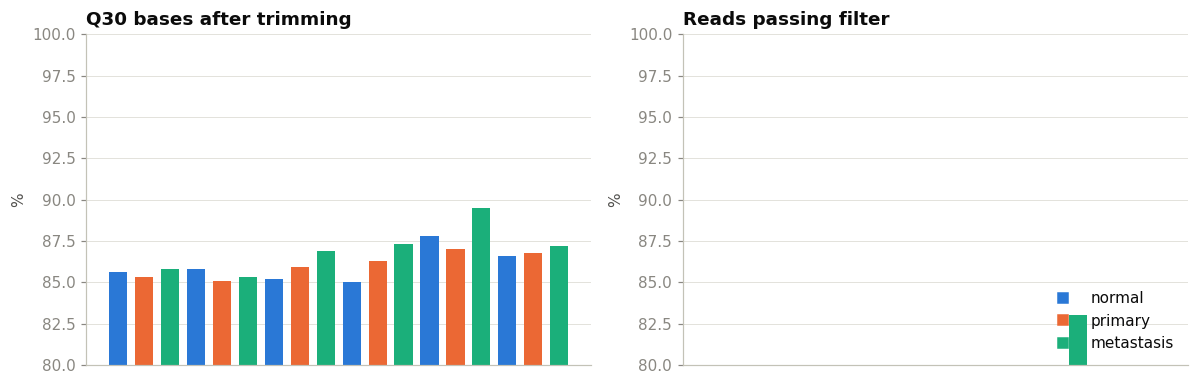

In [ ]:
rows = []
for r in samples.itertuples():
    p = f"{QC}/{r.run}.fastp.json"
    if os.path.exists(p):
        j = json.load(open(p))
        b, a = j["summary"]["before_filtering"], j["summary"]["after_filtering"]
        rows.append({"run": r.run, "patient": r.patient, "tissue": r.tissue,
                     "reads_before": b["total_reads"], "reads_after": a["total_reads"],
                     "q30_after_%": round(a["q30_rate"] * 100, 1), "gc_%": round(a["gc_content"] * 100, 1)})
qc_tbl = pd.DataFrame(rows)
if len(qc_tbl):
    display(qc_tbl) if "display" in globals() else print(qc_tbl)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    cols = [TISSUE_PAL[str(t)] for t in qc_tbl["tissue"]]
    ax[0].bar(range(len(qc_tbl)), qc_tbl["q30_after_%"], color=cols, width=0.7)
    ax[0].set_ylim(80, 100); ax[0].set_title("Q30 bases after trimming"); ax[0].set_ylabel("%")
    ax[0].set_xticks([]); ax[0].grid(axis="x", visible=False)
    ax[1].bar(range(len(qc_tbl)), 100 * qc_tbl["reads_after"] / qc_tbl["reads_before"], color=cols, width=0.7)
    ax[1].set_ylim(80, 100); ax[1].set_title("Reads passing filter"); ax[1].set_ylabel("%")
    ax[1].set_xticks([]); ax[1].grid(axis="x", visible=False)
    handles = [plt.Line2D([], [], marker="s", ls="", color=c, label=t) for t, c in TISSUE_PAL.items() if t in set(qc_tbl["tissue"].astype(str))]
    ax[1].legend(handles=handles, frameon=False, loc="lower right")
    plt.tight_layout(); plt.savefig(f"{OUT}/01_fastp_qc.png"); plt.show()

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 4. Reference and quantification

Reads are quantified with Salmon directly against the GENCODE transcriptome instead of being aligned to the genome. It is much faster and fits in the memory of a free Colab instance, where STAR on the human genome would need around 30 GB of RAM. The `tx2gene` table (transcript to gene ID and symbol) is built from the GENCODE FASTA headers.

Simplification: the index is built without decoys. For a group comparison this has little effect, but it is a limitation.

In [ ]:
fa = f"{REF}/{os.path.basename(GENCODE_URL)}"
if not os.path.exists(fa):
    !wget -q {GENCODE_URL} -O {fa}

tx2gene = {}
with gzip.open(fa, "rt") as f:
    for line in f:
        if line[0] == ">":
            p = line[1:].strip().split("|")
            tx2gene[p[0]] = (p[1], p[5] if len(p) > 5 else p[1], p[7] if len(p) > 7 else "")
gene_info = (pd.DataFrame([(g, s, b) for g, s, b in tx2gene.values()], columns=["gene_id", "symbol", "biotype"])
             .drop_duplicates("gene_id").set_index("gene_id"))
print(f"Transcripts: {len(tx2gene):,}   genes: {len(gene_info):,}")

if not os.path.exists(f"{IDX}/info.json"):
    t0 = time.time()
    subprocess.run(["salmon", "index", "-t", fa, "-i", IDX, "-p", str(THREADS), "--gencode"],
                   check=True, capture_output=True, text=True)
    print(f"Index built in {time.time() - t0:.0f} s")
else:
    print("Index already exists")

Transcripts: 254,070   genes: 63,086
Index built in 1218 s


In [ ]:
def run_salmon(r):
    out = f"{QUANT}/{r.run}"
    if os.path.exists(f"{out}/quant.sf"):
        return
    cmd = ["salmon", "quant", "-i", IDX, "-l", "A", "-p", str(THREADS),
           "--validateMappings", "--seqBias", "-o", out]
    if r.layout == "PAIRED":
        cmd += ["-1", f"{TRIM}/{r.run}_1.fq.gz", "-2", f"{TRIM}/{r.run}_2.fq.gz"]
    else:
        cmd += ["-r", f"{TRIM}/{r.run}_1.fq.gz"]
    subprocess.run(cmd, check=True, capture_output=True, text=True)

t0 = time.time()
for i, r in enumerate(samples.itertuples(), 1):
    run_salmon(r)
    print(f"  Salmon: {i}/{len(samples)}  ({time.time() - t0:.0f} s)")

  Salmon: 1/18  (329 s)
  Salmon: 2/18  (667 s)
  Salmon: 3/18  (993 s)
  Salmon: 4/18  (1313 s)
  Salmon: 5/18  (1648 s)
  Salmon: 6/18  (1950 s)
  Salmon: 7/18  (2257 s)
  Salmon: 8/18  (2582 s)
  Salmon: 9/18  (2919 s)
  Salmon: 10/18  (3224 s)
  Salmon: 11/18  (3556 s)
  Salmon: 12/18  (3904 s)
  Salmon: 13/18  (4253 s)
  Salmon: 14/18  (4601 s)
  Salmon: 15/18  (4970 s)
  Salmon: 16/18  (5285 s)
  Salmon: 17/18  (5621 s)
  Salmon: 18/18  (5955 s)


            mean   min   max
tissue                      
metastasis  92.3  91.6  92.9
normal      90.6  90.0  91.2
primary     91.4  89.7  92.5


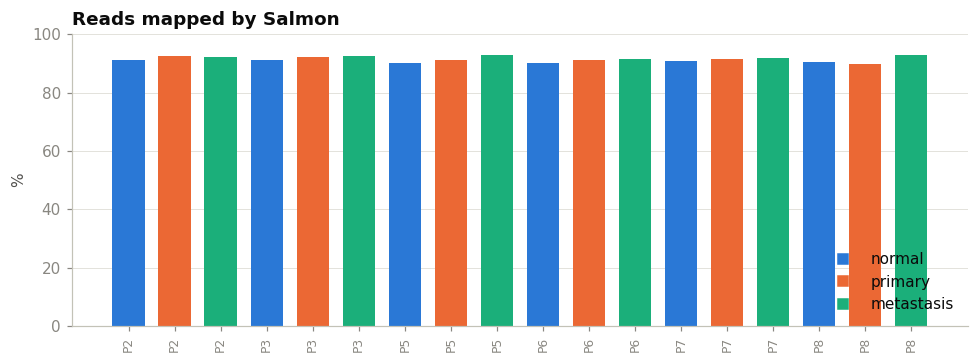

In [ ]:
mp = []
for r in samples.itertuples():
    mi = json.load(open(f"{QUANT}/{r.run}/aux_info/meta_info.json"))
    mp.append({"run": r.run, "patient": r.patient, "tissue": str(r.tissue),
               "processed": mi["num_processed"], "mapped_%": round(mi["percent_mapped"], 1)})
mp = pd.DataFrame(mp)
print(mp.groupby("tissue")["mapped_%"].describe()[["mean", "min", "max"]].round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(range(len(mp)), mp["mapped_%"], color=[TISSUE_PAL[t] for t in mp["tissue"]], width=0.7)
ax.set_title("Reads mapped by Salmon")
ax.set_ylabel("%"); ax.set_ylim(0, 100)
ax.set_xticks(range(len(mp))); ax.set_xticklabels(mp["patient"], rotation=90, fontsize=8)
ax.grid(axis="x", visible=False)
ax.legend(handles=[plt.Line2D([], [], marker="s", ls="", color=c, label=t) for t, c in TISSUE_PAL.items() if t in set(mp["tissue"])],
          frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/02_mapping_rate.png"); plt.show()

In [ ]:
try:
    subprocess.run(["multiqc", QC, QUANT, "-o", f"{OUT}/multiqc", "-f", "-q"], check=True, capture_output=True)
    print("MultiQC:", f"{OUT}/multiqc/multiqc_report.html")
except Exception as e:
    print("MultiQC skipped:", e)

MultiQC: /content/crc_rnaseq/results/multiqc/multiqc_report.html


## 5. Transcripts to genes

Salmon's `quant.sf` gives `NumReads` per transcript. Summing these per gene yields the gene × sample count matrix used for differential expression. Genes with very few reads are dropped, since their statistics are unreliable.

In [ ]:
tx_counts = {}
for r in samples.itertuples():
    q = pd.read_csv(f"{QUANT}/{r.run}/quant.sf", sep="\t", index_col=0)
    tx_counts[r.run] = q["NumReads"]
tx_counts = pd.DataFrame(tx_counts)

gid = pd.Series([tx2gene.get(t, (t, t, ""))[0] for t in tx_counts.index], index=tx_counts.index)
counts = tx_counts.groupby(gid).sum()
print(f"Genes (before filter): {counts.shape[0]:,}   samples: {counts.shape[1]}")

min_samples = max(3, samples["tissue"].value_counts().min())
keep = (counts >= 10).sum(axis=1) >= min_samples
counts_f = counts.loc[keep]
print(f"Genes after filter (≥10 reads in at least {min_samples} samples): {counts_f.shape[0]:,}")

def sym(g):
    return gene_info["symbol"].get(g, g)
counts.to_csv(f"{OUT}/gene_counts_raw.csv")

Genes (before filter): 62,646   samples: 18
Genes after filter (≥10 reads in at least 6 samples): 12,336


## 6. Differential expression

DESeq2 (via `pydeseq2`) with the design `~ patient + tissue`, and two contrasts: primary vs normal, and metastasis vs primary. Each gene gets a log2 fold change and an adjusted p-value (FDR). If `pydeseq2` fails, the cell falls back to a linear model on log-CPM with the same design and says so in its output.

In [ ]:
meta_de = samples.set_index("run")[["patient", "tissue"]].copy()
meta_de["tissue"] = meta_de["tissue"].astype(str)
cnt_mat = counts_f.T.round().astype(int)
cnt_mat = cnt_mat.loc[meta_de.index]

paired = meta_de["patient"].nunique() > 1 and (meta_de.groupby("patient")["tissue"].nunique() > 1).all()
factors = ["patient", "tissue"] if paired else ["tissue"]
design = "~ " + " + ".join(factors)
print("Design:", design)

levels = [t for t in ["normal", "primary", "metastasis"] if t in set(meta_de["tissue"])]
meta_de["tissue"] = pd.Categorical(meta_de["tissue"], categories=levels)
CONTRASTS = []
if "normal" in levels and "primary" in levels:
    CONTRASTS.append(("primary", "normal"))
if "primary" in levels and "metastasis" in levels:
    CONTRASTS.append(("metastasis", "primary"))
print("Contrasts (test vs reference):", CONTRASTS)

DE_METHOD = None
RES = {}
try:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    try:
        from pydeseq2.default_inference import DefaultInference
        inference = DefaultInference(n_cpus=THREADS)
        dds = DeseqDataSet(counts=cnt_mat, metadata=meta_de, design=design, refit_cooks=True, inference=inference, quiet=True)
    except (ImportError, TypeError):
        inference = None
        dds = DeseqDataSet(counts=cnt_mat, metadata=meta_de, design_factors=factors, refit_cooks=True, n_cpus=THREADS, quiet=True)
    dds.deseq2()
    for a, b in CONTRASTS:
        kw = {"inference": inference} if inference is not None else {"n_cpus": THREADS}
        ds = DeseqStats(dds, contrast=["tissue", a, b], quiet=True, **kw)
        ds.summary()
        RES[(a, b)] = ds.results_df.copy()
    norm = pd.DataFrame(dds.layers["normed_counts"], index=cnt_mat.index, columns=cnt_mat.columns).T
    DE_METHOD = "DESeq2 (pydeseq2)"
except Exception as e:
    print("pydeseq2 failed, using fallback:", repr(e)[:200])

if DE_METHOD is None:
    lib = cnt_mat.sum(axis=1)
    norm = (cnt_mat.T / (lib / lib.median())).astype(float)
    logv = np.log2(norm + 1).T.values
    X = pd.get_dummies(meta_de[factors].astype(str), drop_first=True).astype(float)
    X.insert(0, "const", 1.0)
    Xv = X.values; n, p = Xv.shape
    XtX_inv = np.linalg.inv(Xv.T @ Xv)
    B = XtX_inv @ Xv.T @ logv
    s2 = ((logv - Xv @ B) ** 2).sum(axis=0) / (n - p)
    def bh(pv):
        pv = np.asarray(pv); o = np.argsort(pv); r_ = pv[o] * len(pv) / np.arange(1, len(pv) + 1)
        r_ = np.minimum.accumulate(r_[::-1])[::-1]; out = np.empty(len(pv)); out[o] = np.clip(r_, 0, 1); return out
    for a, b in CONTRASTS:
        ca, cb = f"tissue_{a}", f"tissue_{b}"
        c = np.zeros(p)
        if ca in X.columns: c[X.columns.get_loc(ca)] += 1
        if cb in X.columns: c[X.columns.get_loc(cb)] -= 1
        est = c @ B
        se = np.sqrt(s2 * (c @ XtX_inv @ c))
        t = est / se
        pv = 2 * stats.t.sf(np.abs(t), n - p)
        RES[(a, b)] = pd.DataFrame({"baseMean": norm.mean(axis=1).values, "log2FoldChange": est, "stat": t,
                                    "pvalue": pv, "padj": bh(pv)}, index=cnt_mat.columns)
    DE_METHOD = "fallback: OLS on log2 CPM"

print("\nMethod:", DE_METHOD)
for k, r_ in RES.items():
    r_["symbol"] = [sym(g) for g in r_.index]
    sig = (r_["padj"] < FDR_CUT) & (r_["log2FoldChange"].abs() > LFC_CUT)
    print(f"{k[0]} vs {k[1]}: significant genes {sig.sum():,} "
          f"(up: {(sig & (r_['log2FoldChange'] > 0)).sum():,}, down: {(sig & (r_['log2FoldChange'] < 0)).sum():,})")
MAIN = CONTRASTS[0]
res_main = RES[MAIN].sort_values("padj")
res_main.head(15)[["symbol", "baseMean", "log2FoldChange", "padj"]]

Design: ~ patient + tissue
Contrasts (test vs reference): [('primary', 'normal'), ('metastasis', 'primary')]

Method: DESeq2 (pydeseq2)
primary vs normal: significant genes 836 (up: 402, down: 434)
metastasis vs primary: significant genes 215 (up: 179, down: 36)


,symbol,baseMean,log2FoldChange,padj
ENSG00000175832.13,ETV4,59.188864,5.220303,0.000025
ENSG00000163817.17,SLC6A20,22.198342,4.959306,0.000323
ENSG00000271425.9,NBPF10,42.374461,-1.199684,0.000323
ENSG00000111641.13,NOP2,60.244754,2.428471,0.000323
ENSG00000101294.19,HM13,153.460769,1.329655,0.000771
ENSG00000254166.4,CASC19,20.598713,4.779948,0.000771
ENSG00000196660.12,SLC30A10,23.715273,-3.583131,0.000771
ENSG00000187498.17,COL4A1,430.724439,2.427794,0.001424
ENSG00000102837.7,OLFM4,1521.276815,4.580699,0.001581
ENSG00000117091.10,CD48,24.026200,-1.707003,0.002173


## 7. PCA

PCA on log-normalised counts, with grey lines connecting samples from the same patient. The table shows how much of each component's variance is explained by tissue and by patient (η²).

     variance explained, %  η² tissue  η² patient
PC1                   51.4       0.61        0.09
PC2                   11.5       0.60        0.17
PC3                    8.1       0.07        0.69
PC4                    5.3       0.02        0.67
PC5                    3.7       0.02        0.64


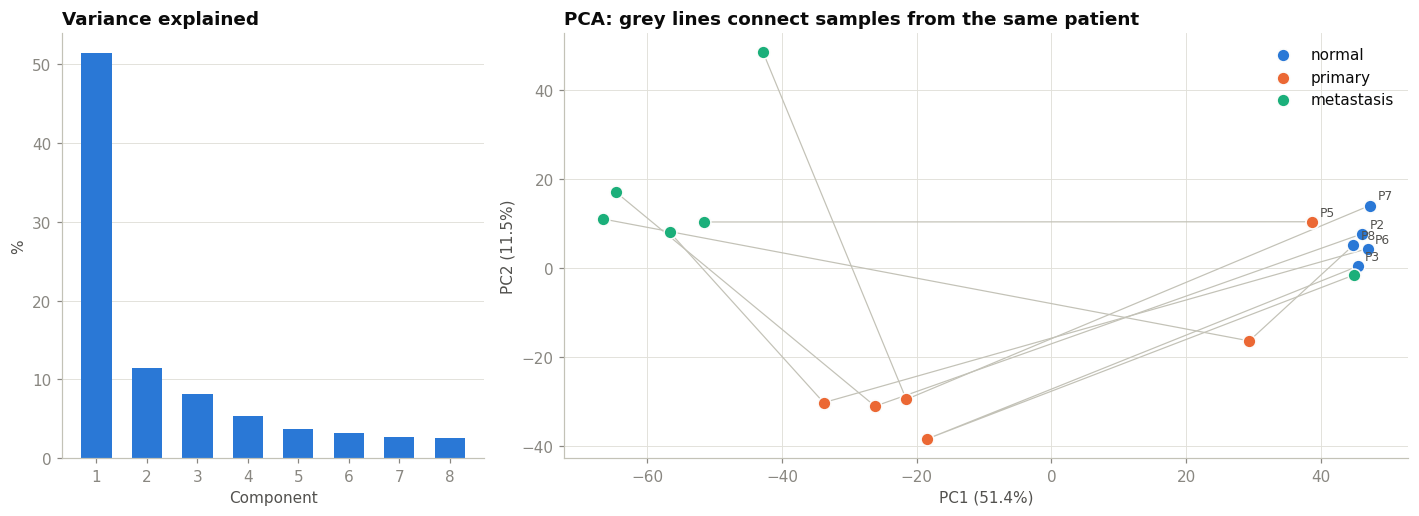

In [ ]:
logn = np.log2(norm + 1)
top = logn.var(axis=1).nlargest(min(1000, logn.shape[0])).index
Xp = logn.loc[top].T
Xp = Xp - Xp.mean(axis=0)
pca = PCA(n_components=min(8, Xp.shape[0] - 1)).fit(Xp)
pcs = pd.DataFrame(pca.transform(Xp), index=Xp.index, columns=[f"PC{i+1}" for i in range(pca.n_components_)])
var = pca.explained_variance_ratio_ * 100
info = samples.set_index("run").loc[pcs.index]

def eta2(values, groups):
    g = pd.Series(values).groupby(np.asarray(groups))
    ss_b = sum(len(x) * (x.mean() - np.mean(values)) ** 2 for _, x in g)
    ss_t = ((np.asarray(values) - np.mean(values)) ** 2).sum()
    return ss_b / ss_t

tab = pd.DataFrame({"variance explained, %": var[:5].round(1),
                    "η² tissue": [round(eta2(pcs[f"PC{i+1}"], info["tissue"].astype(str)), 2) for i in range(5)],
                    "η² patient": [round(eta2(pcs[f"PC{i+1}"], info["patient"]), 2) for i in range(5)]},
                   index=[f"PC{i+1}" for i in range(5)])
print(tab.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [0.7, 1.4]})
axes[0].bar(range(1, len(var) + 1), var, color=BLUE, width=0.6)
axes[0].set_title("Variance explained"); axes[0].set_xlabel("Component"); axes[0].set_ylabel("%")
axes[0].grid(axis="x", visible=False)

ax = axes[1]
for pat, g in info.groupby("patient"):
    order = [t for t in ["normal", "primary", "metastasis"] if t in set(g["tissue"].astype(str))]
    pts = np.array([pcs.loc[g.index[g["tissue"].astype(str) == t][0], ["PC1", "PC2"]].values for t in order])
    ax.plot(pts[:, 0], pts[:, 1], color="#c3c2b7", lw=0.8, zorder=1)
for t, col in TISSUE_PAL.items():
    m = info["tissue"].astype(str) == t
    if m.any():
        ax.scatter(pcs.loc[m.index[m], "PC1"], pcs.loc[m.index[m], "PC2"], s=70, color=col, edgecolor="#fcfcfb", linewidth=1, label=t, zorder=2)
for run, row in info.iterrows():
    if str(row["tissue"]) == "normal":
        ax.annotate(row["patient"], (pcs.loc[run, "PC1"], pcs.loc[run, "PC2"]), xytext=(5, 4), textcoords="offset points", fontsize=8, color=INK2)
ax.set_xlabel(f"PC1 ({var[0]:.1f}%)"); ax.set_ylabel(f"PC2 ({var[1]:.1f}%)")
ax.set_title("PCA: grey lines connect samples from the same patient")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{OUT}/03_pca.png"); plt.show()

## 8. Volcano plots

log2 fold change against -log10 adjusted p-value, with the most significant genes labelled.

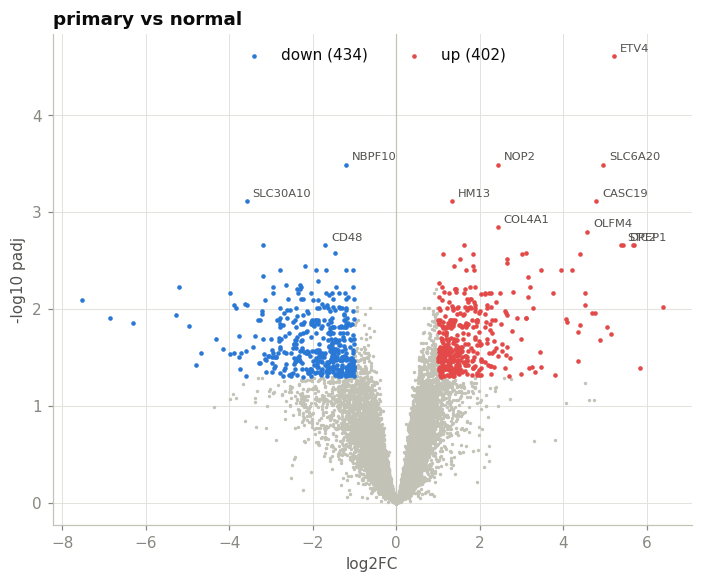

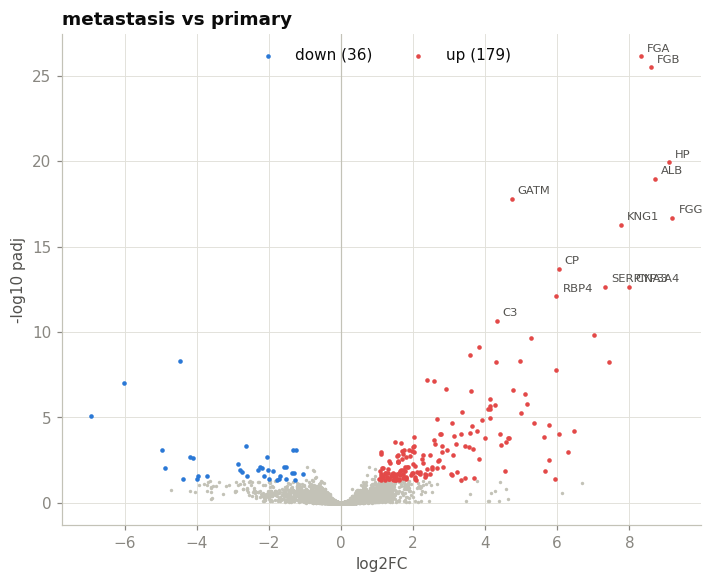

In [ ]:
def volcano(res, title, fname, n_label=12):
    r = res.dropna(subset=["padj"]).copy()
    r["nlp"] = -np.log10(r["padj"].clip(lower=1e-300))
    up = (r["padj"] < FDR_CUT) & (r["log2FoldChange"] > LFC_CUT)
    dn = (r["padj"] < FDR_CUT) & (r["log2FoldChange"] < -LFC_CUT)
    ns = ~(up | dn)
    fig, ax = plt.subplots(figsize=(7.5, 5.8))
    ax.scatter(r.loc[ns, "log2FoldChange"], r.loc[ns, "nlp"], s=5, color="#c3c2b7", linewidth=0)
    ax.scatter(r.loc[dn, "log2FoldChange"], r.loc[dn, "nlp"], s=9, color=BLUE, linewidth=0, label=f"down ({dn.sum()})")
    ax.scatter(r.loc[up, "log2FoldChange"], r.loc[up, "nlp"], s=9, color=RED, linewidth=0, label=f"up ({up.sum()})")
    ax.axvline(0, color="#c3c2b7", lw=0.8)
    for g, row in r.nsmallest(n_label, "padj").iterrows():
        ax.annotate(row["symbol"], (row["log2FoldChange"], row["nlp"]), xytext=(4, 3), textcoords="offset points", fontsize=7.5, color=INK2)
    ax.set_xlabel("log2FC"); ax.set_ylabel("-log10 padj"); ax.set_title(title)
    ax.legend(frameon=False, loc="upper center", ncol=2)
    plt.savefig(f"{OUT}/{fname}"); plt.show()

for i, ((a, b), r_) in enumerate(RES.items(), 1):
    volcano(r_, f"{a} vs {b}", f"04_volcano_{a}_vs_{b}.png")

## 9. Heatmap

The strongest significant genes (equal numbers up and down in tumour), shown as per-gene z-scores. Genes are clustered; samples are ordered by tissue, then by patient.

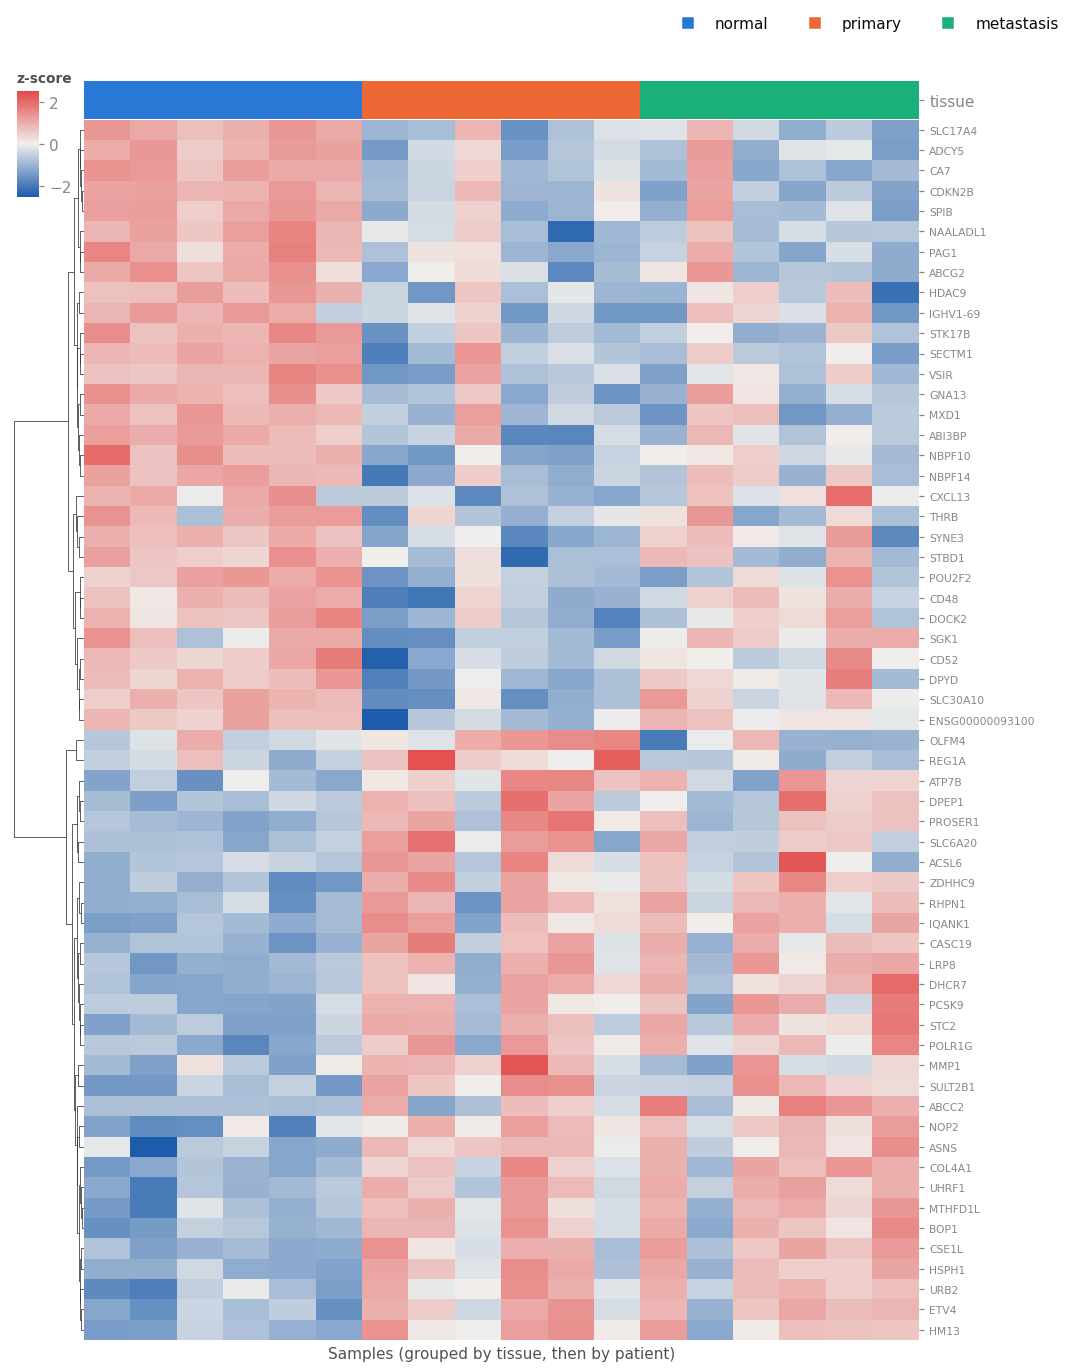

In [ ]:
r = res_main.dropna(subset=["padj"])
sig = r[(r["padj"] < FDR_CUT) & (r["log2FoldChange"].abs() > LFC_CUT)]
if len(sig) < 20:
    sig = r.reindex(r["stat"].abs().sort_values(ascending=False).index).head(60)
genes = list(sig.nlargest(30, "stat").index) + list(sig.nsmallest(30, "stat").index)
genes = list(dict.fromkeys(genes))

order_cols = list(sort_samples(samples, tissue_first=True)["run"])
M = logn.loc[genes, order_cols]
Z = M.sub(M.mean(axis=1), axis=0).div(M.std(axis=1), axis=0)
Z.index = [sym(g) for g in Z.index]
tissue_of = samples.set_index("run")["tissue"].astype(str)
col_colors = pd.Series([TISSUE_PAL[tissue_of[c]] for c in order_cols], index=order_cols, name="tissue")

g = sns.clustermap(Z, cmap=DIV_CMAP, center=0, vmin=-2.5, vmax=2.5, col_cluster=False, row_cluster=True,
                   method="ward", col_colors=col_colors, figsize=(10, 12), xticklabels=False, yticklabels=True,
                   dendrogram_ratio=(0.08, 0.02), cbar_pos=(0.02, 0.88, 0.02, 0.08), linewidths=0)
g.ax_heatmap.set_xlabel("Samples (grouped by tissue, then by patient)")
g.ax_heatmap.tick_params(axis="y", labelsize=7)
g.cax.set_title("z-score", fontsize=9, loc="left", color=INK2)
g.fig.legend(handles=[plt.Line2D([], [], marker="s", ls="", color=c, label=t) for t, c in TISSUE_PAL.items() if t in set(tissue_of)],
             loc="lower right", frameon=False, ncol=3, bbox_to_anchor=(0.98, 0.995))
g.savefig(f"{OUT}/05_heatmap.png"); plt.show()

## 10. Check against known CRC markers

Ten genes with a well-documented direction in colorectal cancer. Markers of normal colon epithelium should be down in tumour (`CA1`, `CA2`, `GUCA2A`, `GUCA2B`, `SLC26A3`, `AQP8`), and genes of the tumour program should be up (`MYC`, `MMP7`, `CLDN1`, `LGR5`). The check is whether the direction in this data matches.

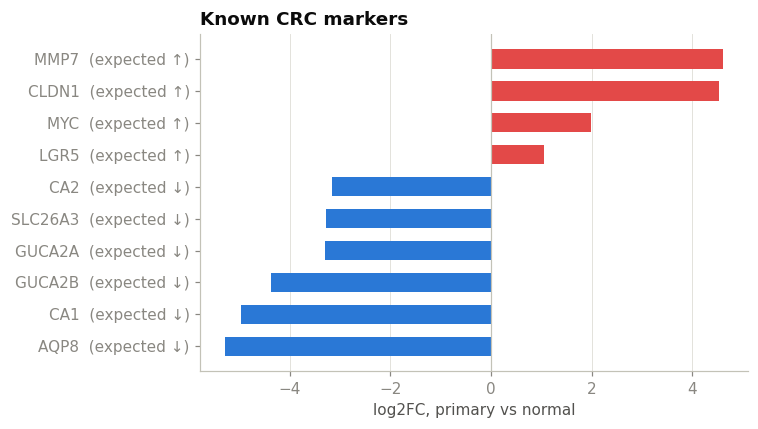

Direction matches the literature for 10 of 10 genes
   gene  expected  log2FC  padj  match
   AQP8        -1  -5.278 0.011   True
    CA1        -1  -4.971 0.015   True
 GUCA2B        -1  -4.372 0.102   True
 GUCA2A        -1  -3.301 0.051   True
SLC26A3        -1  -3.278 0.036   True
    CA2        -1  -3.152 0.033   True
   LGR5         1   1.056 0.335   True
    MYC         1   1.989 0.011   True
  CLDN1         1   4.527 0.009   True
   MMP7         1   4.610 0.087   True


In [ ]:
EXPECTED = {"CA1": -1, "CA2": -1, "GUCA2A": -1, "GUCA2B": -1, "SLC26A3": -1, "AQP8": -1,
            "MYC": 1, "MMP7": 1, "CLDN1": 1, "LGR5": 1}
sym2gid = {s: g for g, s in gene_info["symbol"].items()}
rows = []
for s, d in EXPECTED.items():
    g_ = sym2gid.get(s)
    if g_ in res_main.index:
        rows.append({"gene": s, "expected": d, "log2FC": res_main.loc[g_, "log2FoldChange"], "padj": res_main.loc[g_, "padj"]})
mk = pd.DataFrame(rows).sort_values("log2FC")
if len(mk):
    mk["match"] = np.sign(mk["log2FC"]) == mk["expected"]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.barh(mk["gene"] + np.where(mk["expected"] > 0, "  (expected ↑)", "  (expected ↓)"), mk["log2FC"],
            color=[RED if v > 0 else BLUE for v in mk["log2FC"]], height=0.6)
    ax.axvline(0, color="#c3c2b7", lw=0.8)
    ax.set_xlabel(f"log2FC, {MAIN[0]} vs {MAIN[1]}"); ax.set_title("Known CRC markers")
    ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.savefig(f"{OUT}/06_markers.png"); plt.show()
    print(f"Direction matches the literature for {int(mk['match'].sum())} of {len(mk)} genes")
    print(mk.round(3).to_string(index=False))

## 11. Pathways

Two views of the same contrasts. Enrichr over-representation on GO Biological Process uses the significant genes (top 300 per direction). GSEA on the Hallmark sets uses all genes ranked by test statistic, with no cutoff; a positive NES means the set is shifted towards the first group of the contrast (higher in tumour, for example).

Both need internet access and skip with a message if Enrichr is unreachable.

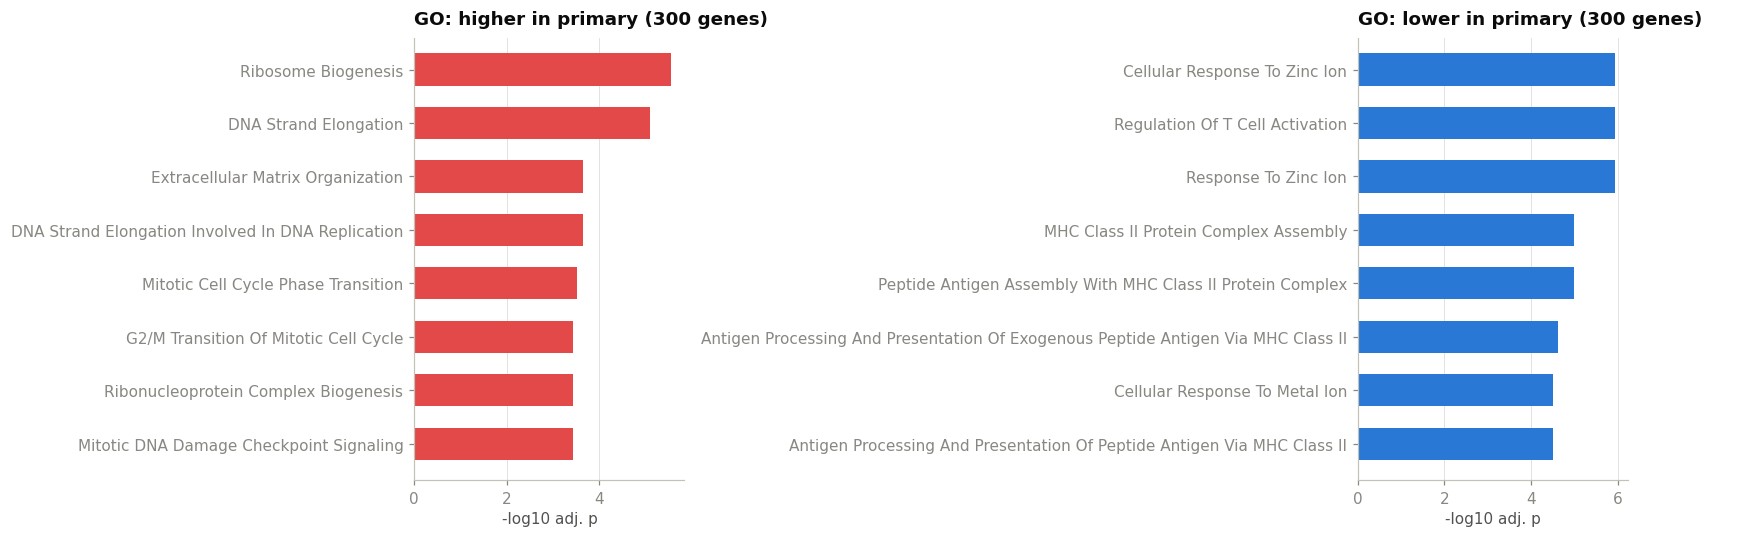

In [ ]:
try:
    import gseapy as gp
    r = res_main.dropna(subset=["padj"])
    sg = r[(r["padj"] < FDR_CUT) & (r["log2FoldChange"].abs() > LFC_CUT)]
    lists = {"higher in " + MAIN[0]: sg[sg["log2FoldChange"] > 0].nlargest(300, "stat")["symbol"].tolist(),
             "lower in " + MAIN[0]: sg[sg["log2FoldChange"] < 0].nsmallest(300, "stat")["symbol"].tolist()}
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    go_tables = {}
    for ax, (name, gl), col in zip(axes, lists.items(), [RED, BLUE]):
        if len(gl) < 10:
            ax.set_title(f"{name}: too few genes"); continue
        enr = gp.enrichr(gene_list=gl, gene_sets=["GO_Biological_Process_2023"], organism="human", outdir=None).results
        go_tables[name] = enr
        top_ = enr.head(8).copy()
        top_["nlp"] = -np.log10(top_["Adjusted P-value"].clip(lower=1e-300))
        ax.barh(top_["Term"].str.replace(r"\s*\(GO:\d+\)", "", regex=True)[::-1], top_["nlp"][::-1], color=col, height=0.6)
        ax.set_title(f"GO: {name} ({len(gl)} genes)"); ax.set_xlabel("-log10 adj. p"); ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.savefig(f"{OUT}/07_go_enrichr.png"); plt.show()
except Exception as e:
    print("Enrichr/GO skipped:", repr(e)[:200])

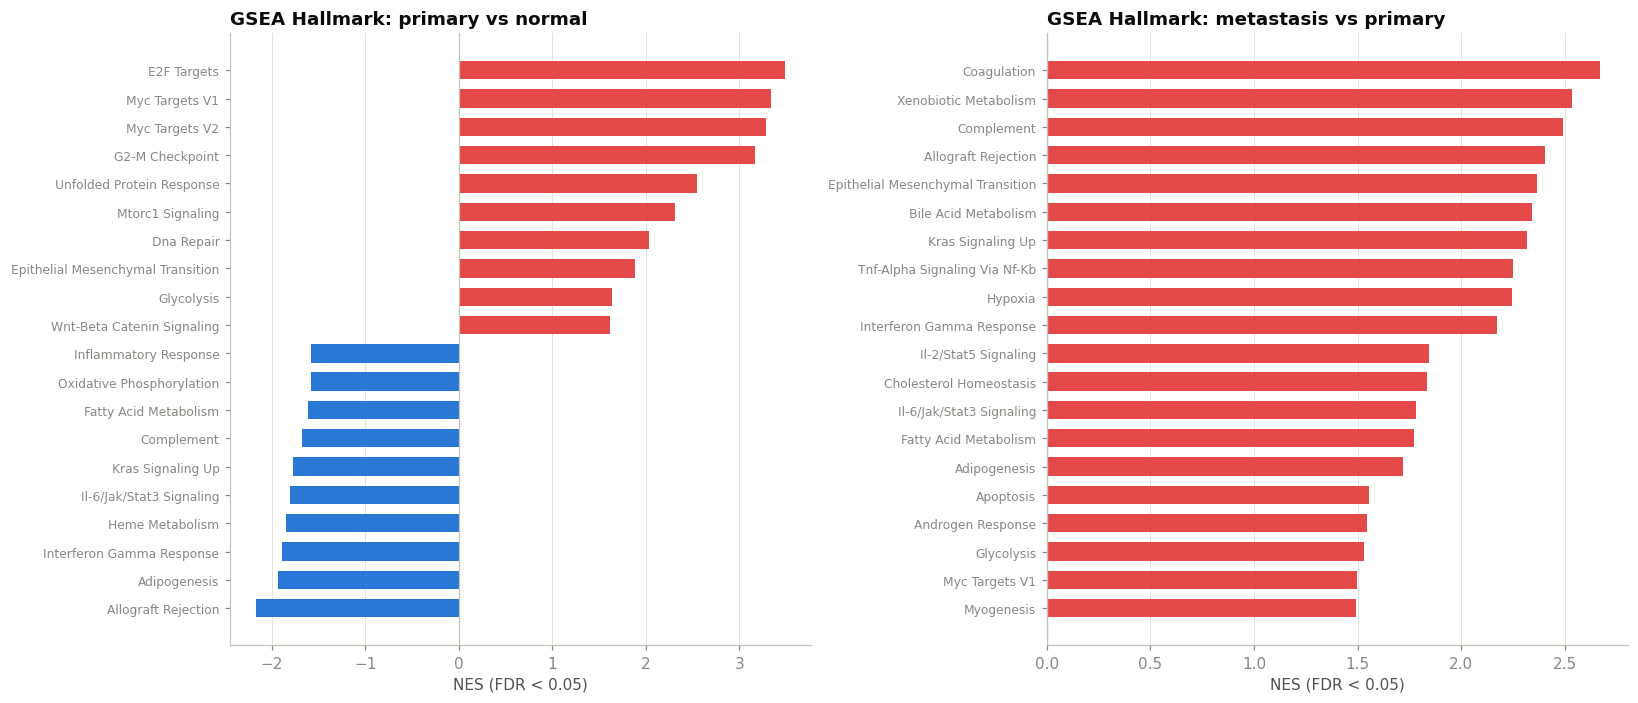

In [ ]:
try:
    import gseapy as gp
    def gsea_hallmark(res, label):
        rnk = res.dropna(subset=["stat"]).copy()
        rnk = rnk[~rnk["symbol"].astype(str).str.startswith("ENSG")]
        rnk = rnk.assign(a=rnk["stat"].abs()).sort_values("a", ascending=False).drop_duplicates("symbol")
        rnk = rnk.set_index("symbol")["stat"].sort_values(ascending=False)
        pre = gp.prerank(rnk=rnk, gene_sets="MSigDB_Hallmark_2020", threads=min(THREADS, 4), min_size=10, max_size=500,
                         permutation_num=1000, seed=7, outdir=None, verbose=False)
        return pre.res2d.copy()

    gs = {}
    fig, axes = plt.subplots(1, len(CONTRASTS), figsize=(7.5 * len(CONTRASTS), 6.5), squeeze=False)
    for ax, (a, b) in zip(axes[0], CONTRASTS):
        tbl = gsea_hallmark(RES[(a, b)], f"{a}_vs_{b}")
        tbl["NES"] = tbl["NES"].astype(float); tbl["FDR q-val"] = tbl["FDR q-val"].astype(float)
        gs[(a, b)] = tbl
        t_ = tbl[tbl["FDR q-val"] < 0.05].sort_values("NES")
        t_ = pd.concat([t_.head(10), t_.tail(10)]).drop_duplicates("Term")
        ax.barh(t_["Term"].str.replace("HALLMARK_", "").str.replace("_", " ").str.title(), t_["NES"],
                color=[RED if v > 0 else BLUE for v in t_["NES"]], height=0.65)
        ax.axvline(0, color="#c3c2b7", lw=0.8)
        ax.set_title(f"GSEA Hallmark: {a} vs {b}"); ax.set_xlabel("NES (FDR < 0.05)"); ax.grid(axis="y", visible=False)
        ax.tick_params(axis="y", labelsize=8)
    plt.tight_layout(); plt.savefig(f"{OUT}/08_gsea_hallmark.png"); plt.show()
except Exception as e:
    print("GSEA skipped:", repr(e)[:200])

## 12. Saving results

In [ ]:
for (a, b), r_ in RES.items():
    r_.sort_values("padj").to_csv(f"{OUT}/de_{a}_vs_{b}.csv")
norm.to_csv(f"{OUT}/normalized_counts.csv.gz")
samples.to_csv(f"{OUT}/samples.csv", index=False)
print(sorted(os.listdir(OUT)))
try:
    from google.colab import files
    shutil.make_archive("/content/crc_results", "zip", OUT)
    files.download("/content/crc_results.zip")
except ImportError:
    pass

['01_fastp_qc.png', '02_mapping_rate.png', '03_pca.png', '04_volcano_metastasis_vs_primary.png', '04_volcano_primary_vs_normal.png', '05_heatmap.png', '06_markers.png', '07_go_enrichr.png', '08_gsea_hallmark.png', 'de_metastasis_vs_primary.csv', 'de_primary_vs_normal.csv', 'gene_counts_raw.csv', 'multiqc', 'normalized_counts.csv.gz', 'samples.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Results

- **Quality.** 90-92% of reads mapped to the transcriptome (mean 90.6% in normal, 91.4% in primary, 92.3% in metastasis). Q30 after trimming was 85-90%.
- **Structure.** PC1 (51% of variance) and PC2 (12%) track tissue (η² 0.61 and 0.60). PC3-PC5 track patient (η² 0.64-0.69), which is why patient is in the model.
- **Tumour vs normal.** 836 genes pass padj < 0.05 and |log2FC| > 1 (402 up, 434 down). Among the top hits are ETV4, OLFM4 and STC2, all up in tumour. All 10 known CRC markers move in the expected direction.
- **Pathways, tumour vs normal.** Up in tumour: E2F targets, MYC targets, G2-M checkpoint, unfolded protein response, mTORC1 signalling, DNA repair. Down: inflammatory response, oxidative phosphorylation, fatty acid metabolism, adipogenesis, interferon gamma response.
- **Metastasis vs primary.** 215 genes (179 up, 36 down), and the strongest are liver genes: FGA, FGB, FGG, HP, ALB, KNG1, CP. Coagulation, complement, xenobiotic and bile acid metabolism dominate the GSEA result. This is host liver tissue in the sample, not a property of the tumour cells, so most of this contrast reflects the organ.

## Limitations

- Only the first N reads per sample and 6 of 18 patients were used, so weak effects and low-expressed genes are detected less well than they would be on the full data.
- The Salmon index has no decoys, and gene-level counts are summed `NumReads` without the length correction that tximport applies.
- Tumour tissue is not pure tumour: stroma and immune cells contribute, and tumour content differs between patients. Without deconvolution, part of the signal reflects tissue composition rather than activity in cancer cells.
- With 6 patients the results illustrate the workflow rather than establish new biology.

## Possible extensions

- All 18 patients and full-depth reads.
- Cell-type deconvolution (CIBERSORT, xCell) and adjusting for it.
- Validation on an independent cohort such as TCGA-COAD, and survival analysis of the resulting signature.
- tximport-style length scaling, compared against the current counts.